In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 30

# Sparsity regularization strength
LAMBDA = 0.0001

print("Device:", device)
print("Lambda:", LAMBDA)

Device: cuda
Lambda: 0.0001


In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from models.sparse_autoencoder import SparseAutoencoder

In [5]:
model = SparseAutoencoder(latent_dim=64).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

reconstruction_criterion = nn.MSELoss()

print(model)

SparseAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [6]:
def sparse_loss(reconstructed, original, z):
    # Reconstruction loss
    reconstruction_loss = reconstruction_criterion(
        reconstructed, original
    )

    # Sparsity penalty (L1)
    sparsity_loss = torch.mean(torch.abs(z))

    # Total loss
    total_loss = reconstruction_loss + LAMBDA * sparsity_loss

    return total_loss, reconstruction_loss, sparsity_loss

In [7]:
transform = transforms.ToTensor()

original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    original_train,
    original_test
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 56000
Validation: 7000
Testing: 7000


In [8]:
def train_sparse_autoencoder(model, train_loader, val_loader, epochs):
    train_losses = []
    val_losses = []

    train_recon_losses = []
    train_sparse_losses = []

    for epoch in range(epochs):

        # Training
        model.train()

        running_total = 0.0
        running_recon = 0.0
        running_sparse = 0.0

        for images, _ in train_loader:
            images = images.to(device)

            optimizer.zero_grad()

            reconstructed, z = model(images)

            total_loss, recon_loss, sparsity_loss = sparse_loss(
                reconstructed, images, z
            )

            total_loss.backward()
            optimizer.step()

            running_total += total_loss.item()
            running_recon += recon_loss.item()
            running_sparse += sparsity_loss.item()

        train_loss = running_total / len(train_loader)
        train_recon = running_recon / len(train_loader)
        train_sparse = running_sparse / len(train_loader)

        train_losses.append(train_loss)
        train_recon_losses.append(train_recon)
        train_sparse_losses.append(train_sparse)

        # Validation
        model.eval()
        val_total = 0.0

        with torch.no_grad():
            for images, _ in val_loader:
                images = images.to(device)

                reconstructed, z = model(images)

                total_loss, _, _ = sparse_loss(
                    reconstructed, images, z
                )

                val_total += total_loss.item()

        val_loss = val_total / len(val_loader)
        val_losses.append(val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {train_loss:.6f} "
            f"Recon: {train_recon:.6f} "
            f"Sparse: {train_sparse:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )

    return train_losses, val_losses, train_recon_losses, train_sparse_losses

In [9]:
train_losses, val_losses, train_recon_losses, train_sparse_losses = train_sparse_autoencoder(
    model,
    train_loader,
    val_loader,
    EPOCHS
)

Epoch [1/30] Train Loss: 0.034217 Recon: 0.034048 Sparse: 1.696822 Val Loss: 0.020294
Epoch [2/30] Train Loss: 0.017854 Recon: 0.017673 Sparse: 1.808445 Val Loss: 0.016268
Epoch [3/30] Train Loss: 0.015130 Recon: 0.014947 Sparse: 1.831416 Val Loss: 0.014451
Epoch [4/30] Train Loss: 0.013670 Recon: 0.013489 Sparse: 1.811676 Val Loss: 0.013272
Epoch [5/30] Train Loss: 0.012633 Recon: 0.012452 Sparse: 1.802759 Val Loss: 0.012427
Epoch [6/30] Train Loss: 0.011875 Recon: 0.011697 Sparse: 1.779786 Val Loss: 0.011727
Epoch [7/30] Train Loss: 0.011248 Recon: 0.011072 Sparse: 1.764473 Val Loss: 0.011167
Epoch [8/30] Train Loss: 0.010748 Recon: 0.010573 Sparse: 1.752059 Val Loss: 0.010750
Epoch [9/30] Train Loss: 0.010312 Recon: 0.010138 Sparse: 1.741889 Val Loss: 0.010347
Epoch [10/30] Train Loss: 0.009984 Recon: 0.009812 Sparse: 1.715506 Val Loss: 0.010046
Epoch [11/30] Train Loss: 0.009688 Recon: 0.009518 Sparse: 1.705054 Val Loss: 0.009988
Epoch [12/30] Train Loss: 0.009453 Recon: 0.009284 S

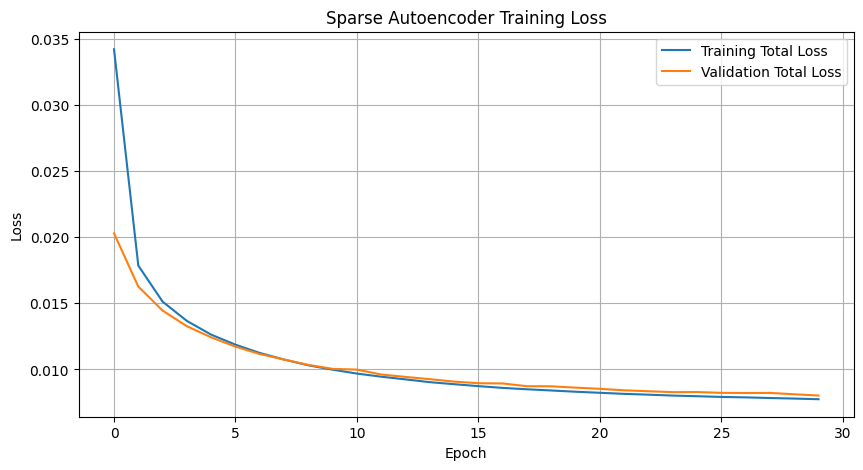

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Total Loss")
plt.plot(val_losses, label="Validation Total Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Sparse Autoencoder Training Loss")

plt.legend()
plt.grid(True)
plt.show()

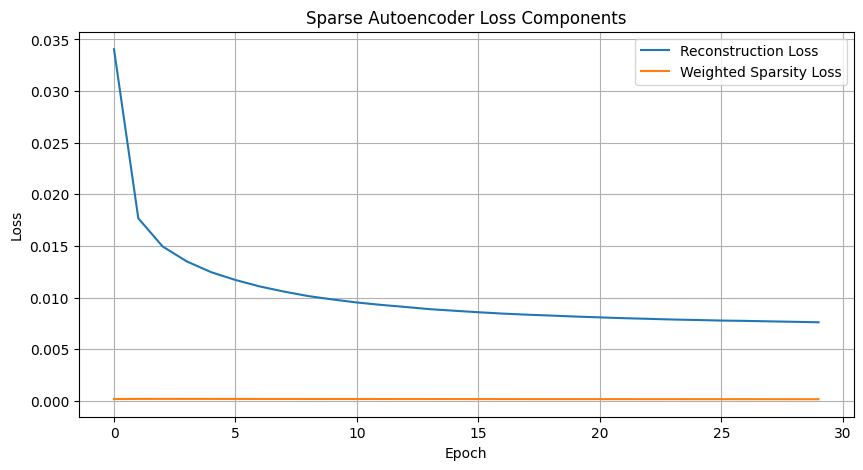

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(train_recon_losses, label="Reconstruction Loss")
plt.plot(
    [LAMBDA * x for x in train_sparse_losses],
    label="Weighted Sparsity Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Sparse Autoencoder Loss Components")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
model.eval()

all_latent = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        _, z = model(images)

        all_latent.append(z.cpu())

all_latent = torch.cat(all_latent, dim=0)

zero_percentage = (
    (all_latent == 0).float().mean().item() * 100
)

print("Latent shape:", all_latent.shape)
print("Zero activation:", f"{zero_percentage:.2f}%")
print("Mean activation:", all_latent.mean().item())

Latent shape: torch.Size([7000, 64])
Zero activation: 27.13%
Mean activation: 1.4998072385787964


In [14]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
import numpy as np

In [15]:
model.eval()

mse_total = 0
psnr_total = 0
ssim_total = 0
total_images = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        reconstructed, z = model(images)

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):
            original = original_np[i].squeeze()
            generated = reconstructed_np[i].squeeze()

            mse_total += np.mean((original - generated) ** 2)

            psnr_total += psnr(
                original, generated, data_range=1.0
            )

            ssim_total += ssim(
                original, generated, data_range=1.0
            )

            total_images += 1

print("MSE:", mse_total / total_images)
print("PSNR:", psnr_total / total_images)
print("SSIM:", ssim_total / total_images)

MSE: 0.007824551782953286
PSNR: 22.124467477630954
SSIM: 0.7987454500926394


In [16]:
import json
import os

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)

# Save model
torch.save(
    model.state_dict(),
    "../results/checkpoints/sparse_autoencoder.pth"
)

# Save metrics
sparse_ae_metrics = {
    "MSE": 0.007824551782953286,
    "PSNR": 22.124467477630954,
    "SSIM": 0.7987454500926394,
    "Zero_Activation_Percentage": 27.13,
    "Lambda": LAMBDA
}

with open("../results/metrics/sparse_ae_metrics.json", "w") as f:
    json.dump(sparse_ae_metrics, f, indent=4)

print("Sparse Autoencoder saved successfully!")

Sparse Autoencoder saved successfully!
